# 03 — Classical regression baselines

Run the project-paths cell first. Paths work from the project root or the notebooks folder.
Existing outputs are retained from the last run; historical path messages may show the former layout.
See [the project README](../README.md) for run order and current limitations.

This historical baseline still uses an all-engine-scaled CSV, uncapped RUL and row-level validation. Its scores are not directly comparable to the corrected LSTM test RMSE.


In [ ]:
from pathlib import Path

# Locate the project whether the kernel starts in the root or notebooks/.
PROJECT_ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / 'requirements.txt').is_file()
     and (folder / 'notebooks').is_dir()
     and (folder / 'README.md').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Start this notebook from inside the Predictive maintenance for IoT project.')
RAW_DATA_DIR = PROJECT_ROOT / 'data' / 'raw' / 'cmapss'
PROCESSED_DATA_DIR = PROJECT_ROOT / 'data' / 'processed'
MODELS_DIR = PROJECT_ROOT / 'models'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
TABLES_DIR = PROJECT_ROOT / 'reports' / 'tables'
print(f'Project root: {PROJECT_ROOT}')


In [2]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# Models
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from xgboost import XGBRegressor

# Models Implementation and instantiation


In [ ]:
df = pd.read_csv(PROCESSED_DATA_DIR / 'ml_baselines' / 'df_clean_FD001.csv')
df.head(5)

,unit_number,time_in_cycles,s_2,s_3,s_4,s_7,s_8,s_11,s_12,s_13,s_14,s_15,s_17,s_20,s_21,RUL
0,1,1,0.183735,0.406802,0.309757,0.726248,0.242424,0.369048,0.633262,0.205882,0.199608,0.363986,0.333333,0.713178,0.724662,191
1,1,2,0.283133,0.453019,0.352633,0.628019,0.212121,0.380952,0.765458,0.279412,0.162813,0.411312,0.333333,0.666667,0.731014,190
2,1,3,0.343373,0.369523,0.370527,0.710145,0.272727,0.250000,0.795309,0.220588,0.171793,0.357445,0.166667,0.627907,0.621375,189
3,1,4,0.343373,0.256159,0.331195,0.740741,0.318182,0.166667,0.889126,0.294118,0.174889,0.166603,0.333333,0.573643,0.662386,188
4,1,5,0.349398,0.257467,0.404625,0.668277,0.242424,0.255952,0.746269,0.235294,0.174734,0.402078,0.416667,0.589147,0.704502,187


In [ ]:


# 1. Define Features and Target
# We use the normalized sensor columns you created
features = [col for col in df.columns if 's_' in col]
target = 'RUL' # We use the clipped RUL (max 125)
X = df[features]
y = df[target]
groups = df['unit_number'] # We need this to split data safely

print(f"Features selected: {len(features)}")
print(X.head())

Features selected: 13
        s_2       s_3       s_4       s_7       s_8      s_11      s_12  \
0  0.183735  0.406802  0.309757  0.726248  0.242424  0.369048  0.633262   
1  0.283133  0.453019  0.352633  0.628019  0.212121  0.380952  0.765458   
2  0.343373  0.369523  0.370527  0.710145  0.272727  0.250000  0.795309   
3  0.343373  0.256159  0.331195  0.740741  0.318182  0.166667  0.889126   
4  0.349398  0.257467  0.404625  0.668277  0.242424  0.255952  0.746269   

       s_13      s_14      s_15      s_17      s_20      s_21  
0  0.205882  0.199608  0.363986  0.333333  0.713178  0.724662  
1  0.279412  0.162813  0.411312  0.333333  0.666667  0.731014  
2  0.220588  0.171793  0.357445  0.166667  0.627907  0.621375  
3  0.294118  0.174889  0.166603  0.333333  0.573643  0.662386  
4  0.235294  0.174734  0.402078  0.416667  0.589147  0.704502  


In [ ]:
# 2. Split Data by Unit ID (80% Train, 20% Validation)
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)

# This generates the indices to split the dataframe
train_idx, val_idx = next(gss.split(X, y, groups))

X_train = X.iloc[train_idx]
y_train= y.iloc[train_idx]
X_val = X.iloc[val_idx]
y_val = y.iloc[val_idx]

print(f"Training Shape: {X_train.shape}")
print(f"Validation Shape: {X_val.shape}")

Training Shape: (16561, 13)
Validation Shape: (4070, 13)


In [ ]:
# 2. DEFINE THE METRICS FUNCTION
def evaluate_model(y_true, y_pred, model_name):
    """
    Calculates all regression metrics including a custom 'Accuracy'
    """
    # Standard Regression Metrics
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    # Custom "Accuracy": % of predictions within +/- 20 cycles of truth
    # This acts as a proxy for "Accuracy" and "Precision" in regression
    threshold = 20
    errors = np.abs(y_true - y_pred)
    accuracy_within_threshold = np.mean(errors <= threshold) * 100
    
    print(f"--- {model_name} Performance ---")
    print(f"1. Accuracy (+/- 20 cycles): {accuracy_within_threshold:.2f}%")
    print(f"2. MAE (Mean Abs Error):     {mae:.2f}")
    print(f"3. MSE (Mean Sq Error):      {mse:.2f}")
    print(f"4. RMSE (Root MSE):          {rmse:.2f}")
    print(f"5. R² (Goodness of Fit):     {r2:.4f}")
    print("-" * 30)
    
    return y_pred

In [ ]:
# Helper function to plot results
def plot_results(y_true, y_pred, title):
    # Plot just the first unit in the validation set for clarity
    val_unit = df.iloc[val_idx]['unit_number'].unique()[0]
    mask = df.iloc[val_idx]['unit_number'] == val_unit
    
    plt.figure(figsize=(10, 5))
    plt.plot(y_true[mask].values, label='Actual RUL', color='black', linewidth=2)
    plt.plot(y_pred[mask], label='Prediction', linestyle='--', color='red')
    plt.title(f"{title} (Unit {val_unit})")
    plt.ylabel('RUL')
    plt.xlabel('Cycles')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Linear regression

--- Linear Regression Performance ---
1. Accuracy (+/- 20 cycles): 40.29%
2. MAE (Mean Abs Error):     30.14
3. MSE (Mean Sq Error):      1459.42
4. RMSE (Root MSE):          38.20
5. R² (Goodness of Fit):     0.6614
------------------------------


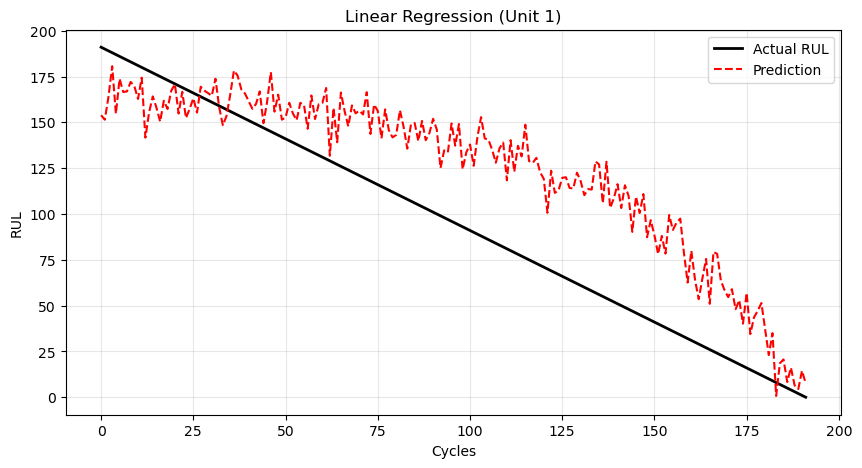

In [ ]:
# Train
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predict
y_pred_lr = lr.predict(X_val)

# Evaluate (Calculates all your requested metrics)
evaluate_model(y_val, y_pred_lr, "Linear Regression")

# 4. Plot
plot_results(y_val, y_pred_lr, "Linear Regression")

Training SVR...
--- SVR Performance ---
1. Accuracy (+/- 20 cycles): 53.51%
2. MAE (Mean Abs Error):     25.30
3. MSE (Mean Sq Error):      1244.99
4. RMSE (Root MSE):          35.28
5. R² (Goodness of Fit):     0.7112
------------------------------


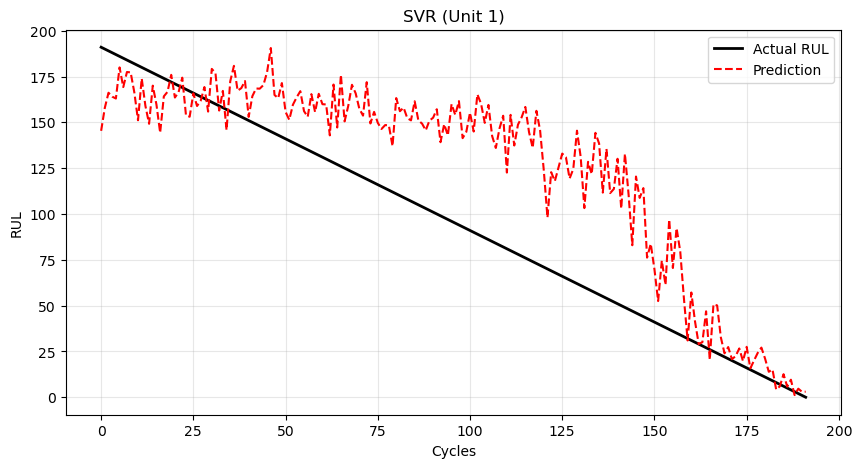

In [ ]:
# Train (Using RBF kernel for non-linear capabilities)
svr = SVR(kernel='rbf', C=10, epsilon=0.1)
print("Training SVR...")
svr.fit(X_train, y_train)

# Predict
y_pred_svr = svr.predict(X_val)

# Evaluate
evaluate_model(y_val, y_pred_svr, "SVR")
plot_results(y_val, y_pred_svr, "SVR")

# Random Forest Regressor

Training Random Forest...
--- Random Forest Performance ---
1. Accuracy (+/- 20 cycles): 52.06%
2. MAE (Mean Abs Error):     26.11
3. MSE (Mean Sq Error):      1273.95
4. RMSE (Root MSE):          35.69
5. R² (Goodness of Fit):     0.7044
------------------------------


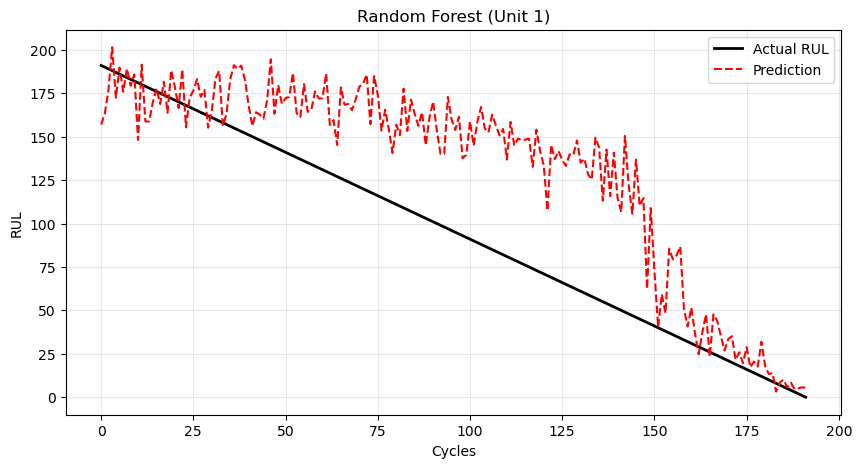

In [ ]:
# Train
rf = RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42)
print("Training Random Forest...")
rf.fit(X_train, y_train)

# Predict
y_pred_rf = rf.predict(X_val)

# Evaluate
evaluate_model(y_val, y_pred_rf, "Random Forest")
# 4. Plot
plot_results(y_val, y_pred_rf, "Random Forest")

Training XGBoost...
--- XGBoost Performance ---
1. Accuracy (+/- 20 cycles): 51.89%
2. MAE (Mean Abs Error):     26.05
3. MSE (Mean Sq Error):      1272.28
4. RMSE (Root MSE):          35.67
5. R² (Goodness of Fit):     0.7048
------------------------------


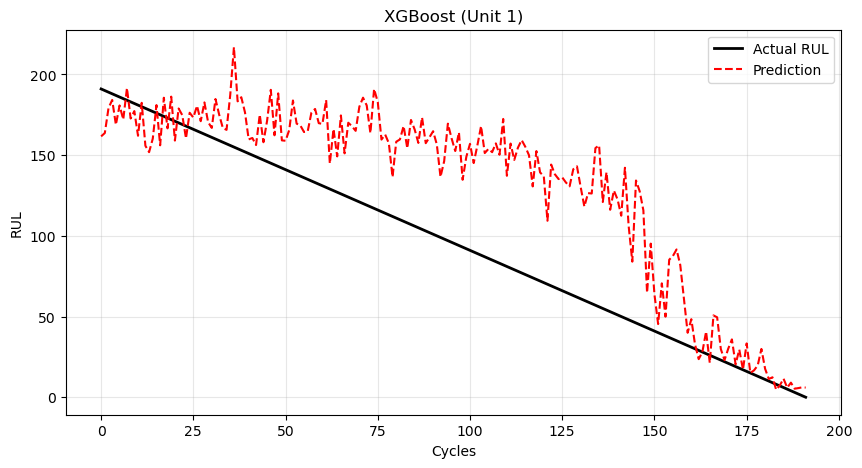

In [ ]:

# 1. Train
xgb_model = XGBRegressor(n_estimators=200, learning_rate=0.04, max_depth=6, n_jobs=-1, random_state=42)
print("Training XGBoost...")
xgb_model.fit(X_train, y_train)

# 2. Predict
y_pred_xgb = xgb_model.predict(X_val)

# 3. Evaluate
evaluate_model(y_val, y_pred_xgb, "XGBoost")

# 4. Plot
plot_results(y_val, y_pred_xgb, "XGBoost")

From the result we get that No matter how fancy the algorithm is, if you feed it only the current sensor data (without the history/window), the best any model can do is guess within $\pm 35$ cycles.

# The Solution: Deep Learning (LSTM)
We need to smash through that "RMSE 35" wall. Our goal for the Deep Learning model is an RMSE below 20 and an Accuracy above 80%.

To do this, we must use the Time-Series (Sliding Window) data i prepared earlier.